# Decision trees

This time with embeddings from a [Serbian language SentenceTransformer](https://huggingface.co/djovak/embedic-large). Results not so great, interestingly it can't do the same as what logistic regression did on the same embeddings (a very good result).

majority baseline: vilifying_opponents
                      precision  recall  f1-score
nothing                   0.000   0.000     0.000
personality_cult          0.000   0.000     0.000
vilifying_eu              0.000   0.000     0.000
vilifying_neighbours      0.000   0.000     0.000
vilifying_opponents       0.538   1.000     0.700
accuracy                  0.538   0.538     0.538
macro avg                 0.108   0.200     0.140
weighted avg              0.289   0.538     0.376
label
vilifying_opponents     245
nothing                  84
vilifying_neighbours     69
personality_cult         38
vilifying_eu             19
Name: count, dtype: int64
                      precision  recall  f1-score
nothing                   0.273   0.273     0.273
personality_cult          0.167   0.429     0.240
vilifying_eu              0.000   0.000     0.000
vilifying_neighbours      0.333   0.450     0.383
vilifying_opponents       0.726   0.634     0.677
accuracy                  0.477   0.477

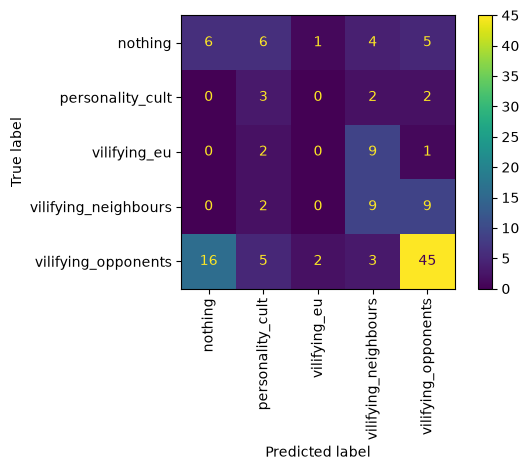

In [13]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.tree import DecisionTreeClassifier

sys.path.insert(0, str(Path.cwd()))

from data import make_groups
from evaluation import baseline_predictions, evaluate, split_data

data = pd.read_csv("../data/processed/headlines_with_embedic_large.csv")
data["group"] = make_groups(data)
labels = sorted(data["label"].unique())
embeddings = np.stack(data["embedding"].map(json.loads).to_numpy()).astype(np.float32)
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]
X_train = embeddings[train_indices]
X_test = embeddings[test_indices]

majority_label, baseline = baseline_predictions(train["label"], len(test))
print(f"majority baseline: {majority_label}")
print(pd.DataFrame(evaluate(test["label"], baseline, labels)["report"]).T[["precision", "recall", "f1-score"]].round(3))
print(data["label"].value_counts())

classifier = DecisionTreeClassifier(random_state=42)
classifier.fit(X_train, train["label"])
predictions = classifier.predict(X_test)

print(
    pd.DataFrame(evaluate(test["label"], predictions, labels)["report"])
    .T[["precision", "recall", "f1-score"]]
    .round(3)
)
print(f"Decision tree test accuracy: {accuracy_score(test['label'], predictions):.3f}")
print(f"Majority baseline test accuracy: {accuracy_score(test['label'], baseline):.3f}")

ConfusionMatrixDisplay.from_predictions(
    test["label"], predictions, labels=labels, xticks_rotation="vertical"
)
plt.tight_layout()
plt.show()

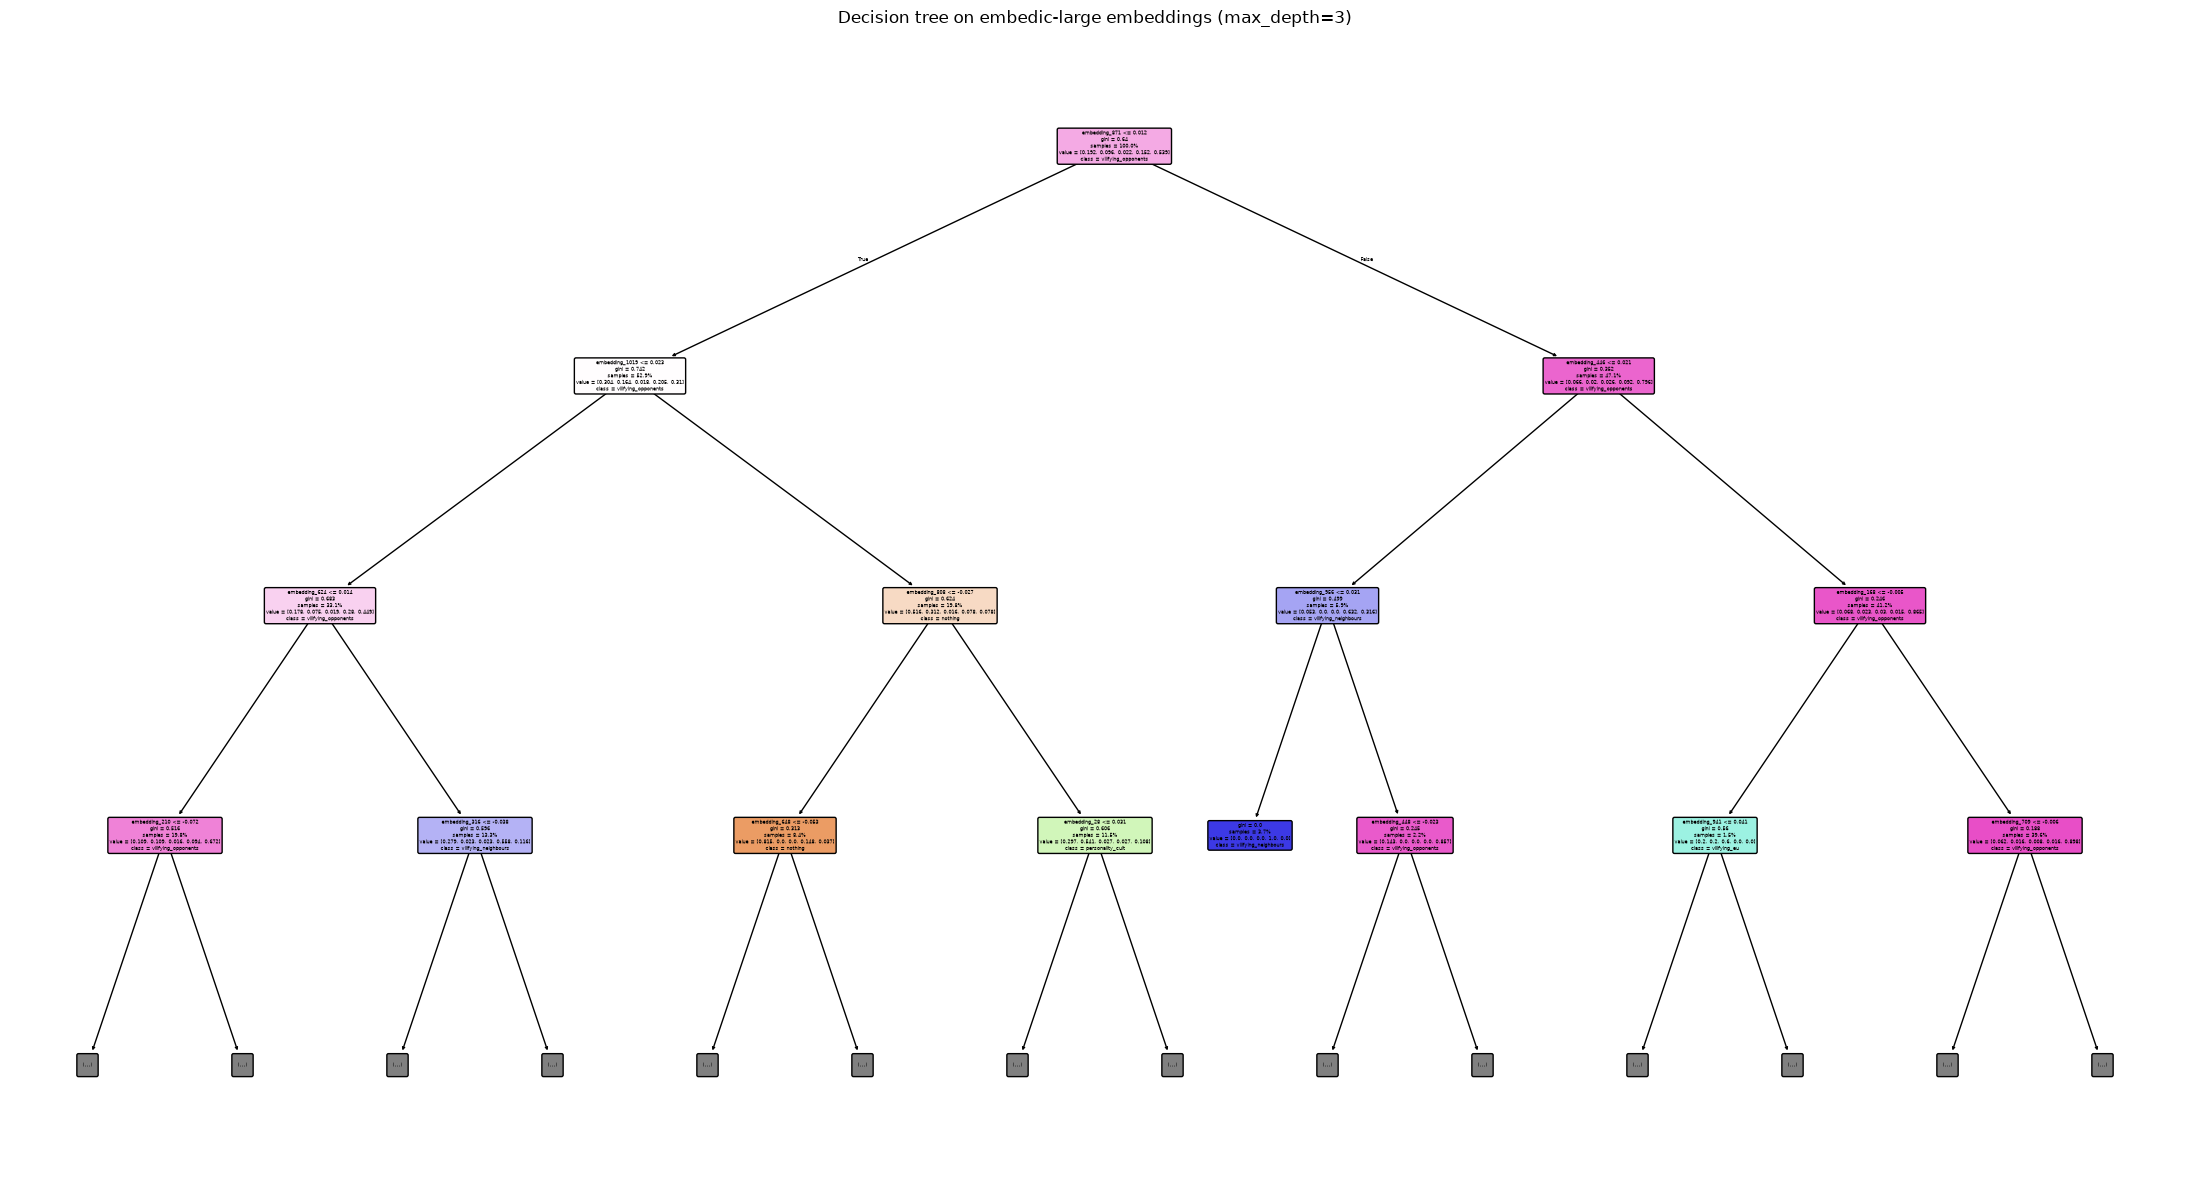

Tree nodes: 89
Tree depth: 9
|--- embedding_871 <= 0.01
|   |--- embedding_1019 <= 0.02
|   |   |--- embedding_624 <= 0.01
|   |   |   |--- embedding_210 <= -0.07
|   |   |   |   |--- embedding_153 <= -0.01
|   |   |   |   |   |--- embedding_529 <= 0.01
|   |   |   |   |   |   |--- weights: [0.00, 3.00, 0.00, 0.00, 0.00] class: personality_cult
|   |   |   |   |   |--- embedding_529 >  0.01
|   |   |   |   |   |   |--- weights: [0.00, 0.00, 0.00, 3.00, 0.00] class: vilifying_neighbours
|   |   |   |   |--- embedding_153 >  -0.01
|   |   |   |   |   |--- embedding_569 <= -0.02
|   |   |   |   |   |   |--- weights: [6.00, 0.00, 0.00, 0.00, 0.00] class: nothing
|   |   |   |   |   |--- embedding_569 >  -0.02
|   |   |   |   |   |   |--- embedding_136 <= -0.04
|   |   |   |   |   |   |   |--- weights: [0.00, 0.00, 1.00, 0.00, 0.00] class: vilifying_eu
|   |   |   |   |   |   |--- embedding_136 >  -0.04
|   |   |   |   |   |   |   |--- weights: [0.00, 0.00, 0.00, 0.00, 1.00] class: vilifyin

In [14]:
from sklearn.tree import plot_tree, export_text

tree = classifier
feature_names = [f"embedding_{index}" for index in range(X_train.shape[1])]

plt.figure(figsize=(22, 12))
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=tree.classes_,
    filled=True,
    rounded=True,
    proportion=True,
    max_depth=3,
)
plt.title("Decision tree on embedic-large embeddings (max_depth=3)")
plt.tight_layout()
plt.show()

print(f"Tree nodes: {tree.tree_.node_count}")
print(f"Tree depth: {tree.tree_.max_depth}")
print(export_text(tree, feature_names=feature_names, show_weights=True)[:4000])

This decision tree uses dense sentence embeddings from `djovak/embedic-large`, not TF-IDF word features. Each `embedding_N` feature is one learned coordinate in the headline's embedding vector; individual coordinates are not words and generally do not have a simple human-readable interpretation.

A rule such as `embedding_384 <= 0.04` means the model compares the value of that embedding coordinate with the threshold and routes the headline through one branch or the other. It does not mean a word appears with a particular frequency or importance.

The tree can show which embedding dimensions it uses to partition this training set, but those splits alone do not establish that a particular topic or framing caused the prediction.

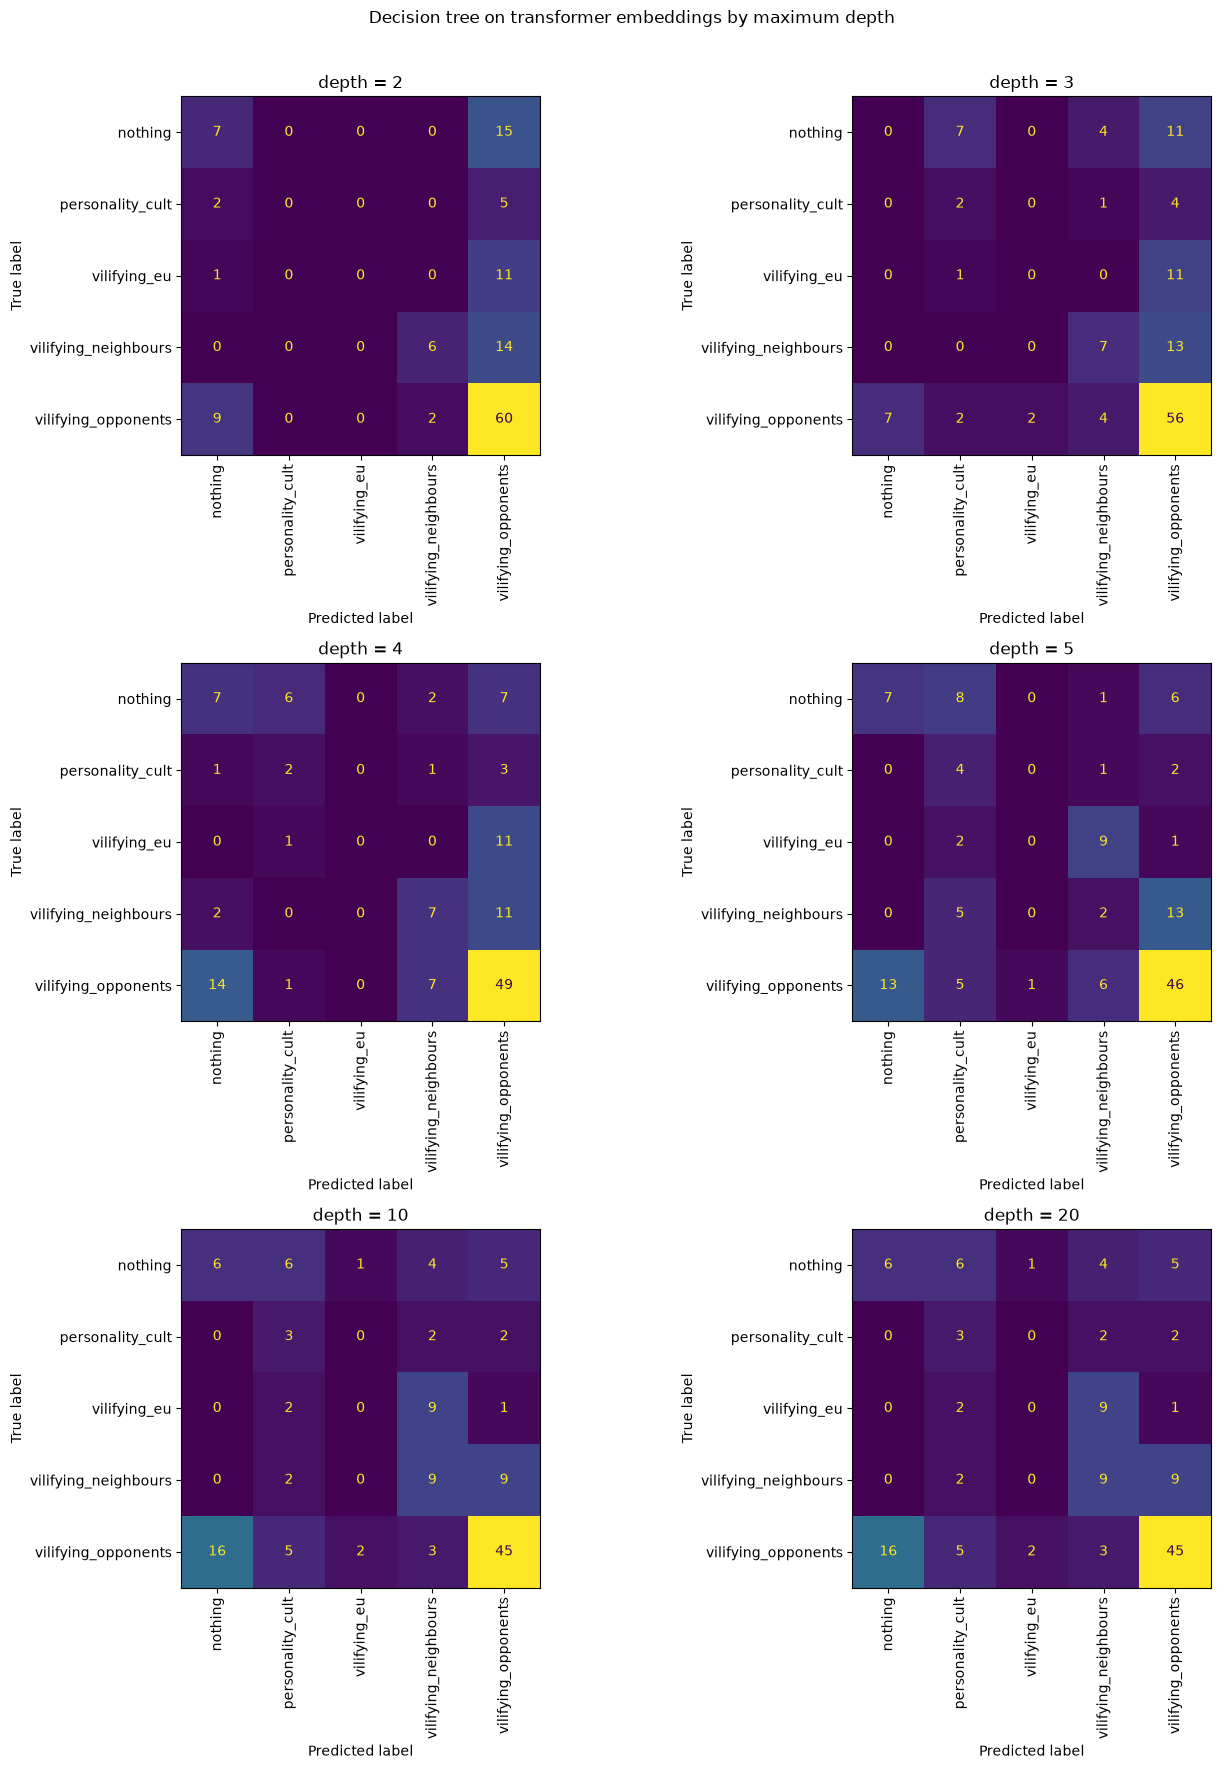

In [15]:
decision_tree_depths = [2, 3, 4, 5, 10, 20]

figure, axes = plt.subplots(3, 2, figsize=(14, 18))

for axis, depth in zip(axes.flat, decision_tree_depths):
    depth_tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    depth_tree.fit(X_train, train["label"])
    depth_predictions = depth_tree.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        test["label"],
        depth_predictions,
        ax=axis,
        labels=labels,
        xticks_rotation="vertical",
        colorbar=False,
    )
    axis.set_title(f"depth = {depth}")

figure.suptitle("Decision tree on transformer embeddings by maximum depth")
figure.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Best settings: {'class_weight': {'nothing': 8, 'personality_cult': 8, 'vilifying_eu': 1.0, 'vilifying_neighbours': 1.0, 'vilifying_opponents': 1.0}, 'max_depth': 3, 'min_samples_leaf': 1}
CV ['nothing', 'personality_cult'] recall: 0.449
Test nothing precision: 0.185
Test nothing recall:    0.545
Test nothing examples:  22
Test personality_cult precision: 0.070
Test personality_cult recall:    0.429
Test personality_cult examples:  7


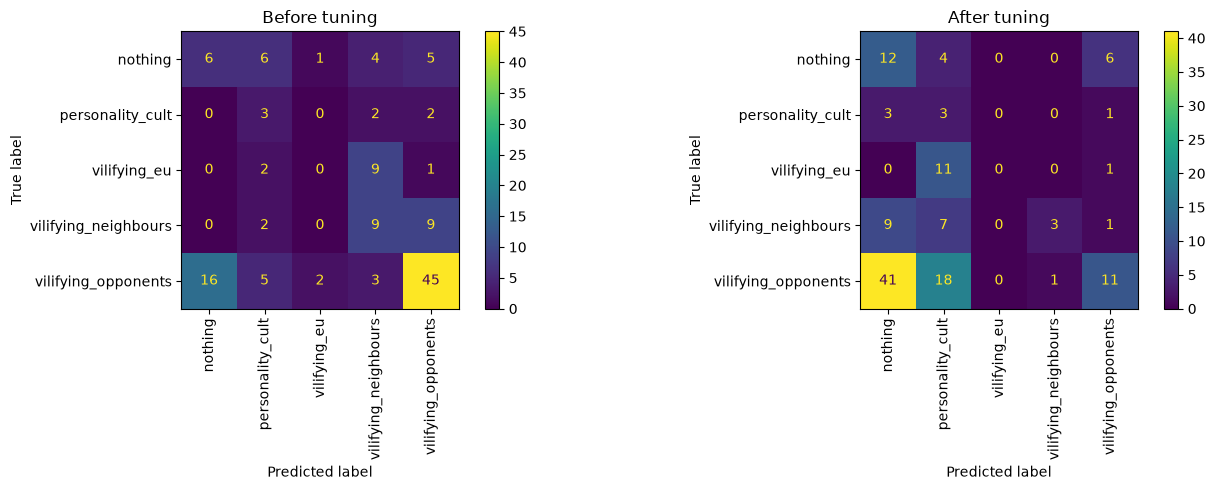

In [11]:
from sklearn.metrics import make_scorer, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold

targets = ["nothing", "personality_cult"]

target_class_weights = [
    {label: (weight if label in targets else 1.0) for label in labels}
    for weight in [1, 2, 4, 8]
]

search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid={
        "max_depth": [3, 5, 10, None],
        "min_samples_leaf": [1, 2, 4, 8],
        "class_weight": [None, "balanced", *target_class_weights],
    },
    scoring=make_scorer(
        recall_score,
        labels=targets,
        average="micro",
        zero_division=0,
    ),
    cv=GroupKFold(n_splits=3),
    refit=True,
    n_jobs=-1,
)

search.fit(X_train, train["label"], groups=train["group"])

tuned_model = search.best_estimator_
tuned_predictions = tuned_model.predict(X_test)

print("Best settings:", search.best_params_)
print(f"CV {targets} recall: {search.best_score_:.3f}")

for target in targets:
    y_true = test["label"].eq(target)
    y_pred = pd.Series(tuned_predictions, index=test.index).eq(target)

    print(f"Test {target} precision: {precision_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"Test {target} recall:    {recall_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"Test {target} examples:  {y_true.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    test["label"], predictions, labels=labels, xticks_rotation="vertical", ax=axes[0]
)
axes[0].set_title("Before tuning")

ConfusionMatrixDisplay.from_predictions(
    test["label"], tuned_predictions, labels=labels, xticks_rotation="vertical", ax=axes[1]
)
axes[1].set_title("After tuning")

plt.tight_layout()
plt.show()

Best settings: {'class_weight': {'nothing': 8, 'personality_cult': 1.0, 'vilifying_eu': 1.0, 'vilifying_neighbours': 1.0, 'vilifying_opponents': 1.0}, 'max_depth': 3, 'min_samples_leaf': 1}
CV ['nothing'] recall: 0.634
Test nothing precision: 0.246
Test nothing recall:    0.727
Test nothing examples:  22


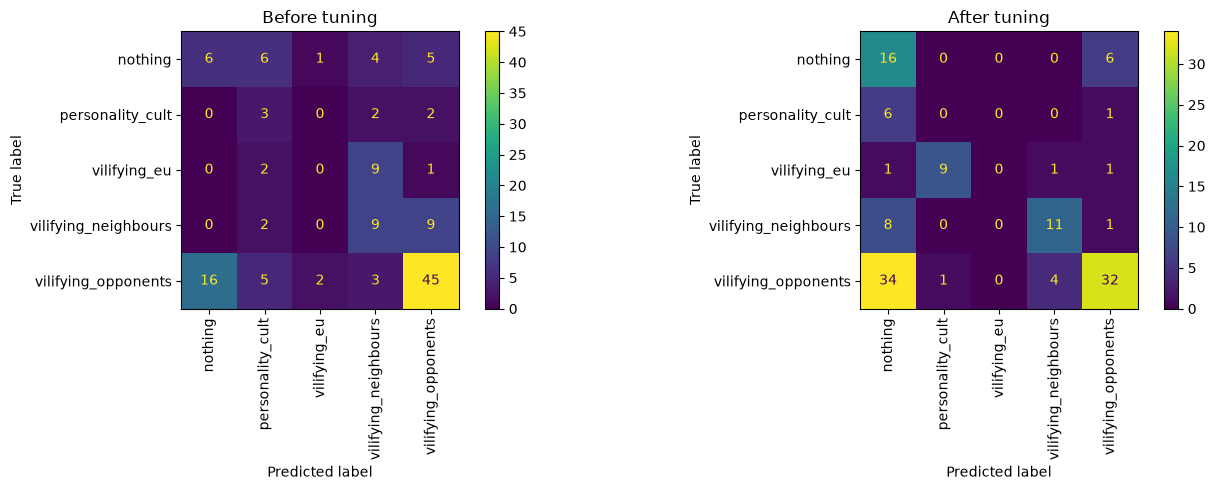

In [16]:
from sklearn.metrics import make_scorer, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold

targets = ["nothing"]

target_class_weights = [
    {label: (weight if label in targets else 1.0) for label in labels}
    for weight in [1, 2, 4, 8]
]

search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid={
        "max_depth": [3, 5, 10, None],
        "min_samples_leaf": [1, 2, 4, 8],
        "class_weight": [None, "balanced", *target_class_weights],
    },
    scoring=make_scorer(
        recall_score,
        labels=targets,
        average="micro",
        zero_division=0,
    ),
    cv=GroupKFold(n_splits=3),
    refit=True,
    n_jobs=-1,
)

search.fit(X_train, train["label"], groups=train["group"])

tuned_model = search.best_estimator_
tuned_predictions = tuned_model.predict(X_test)

print("Best settings:", search.best_params_)
print(f"CV {targets} recall: {search.best_score_:.3f}")

for target in targets:
    y_true = test["label"].eq(target)
    y_pred = pd.Series(tuned_predictions, index=test.index).eq(target)

    print(f"Test {target} precision: {precision_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"Test {target} recall:    {recall_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"Test {target} examples:  {y_true.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    test["label"], predictions, labels=labels, xticks_rotation="vertical", ax=axes[0]
)
axes[0].set_title("Before tuning")

ConfusionMatrixDisplay.from_predictions(
    test["label"], tuned_predictions, labels=labels, xticks_rotation="vertical", ax=axes[1]
)
axes[1].set_title("After tuning")

plt.tight_layout()
plt.show()